# Notebook 04 – Machine Learning: dự đoán đơn hàng lỗ trên Superstore

## Mục 4.3. Ứng dụng Machine Learning

**Mục tiêu:** trả lời **Câu hỏi 4** – có dự đoán trước được dòng hàng bị lỗ (Profit < 0) ngay khi lên đơn không, mô hình nào tốt nhất và yếu tố nào quan trọng nhất?

**Đầu vào:** `data/processed/superstore_clean.csv` (9.993 dòng, kết quả Chương 3). Đơn vị dự đoán là **dòng hàng** (một mặt hàng trong một đơn), khớp với cách đếm "đơn lỗ" ở Chương 3 và mục 4.1.

**Đầu ra:** 4 hình `figures/4_3_*.png` và các bảng `reports/4_3_*.csv`.

**Quy ước:** `random_state = 42` ở mọi bước ngẫu nhiên; chỉ dùng thông tin **biết được khi lên đơn**; toàn bộ tiền xử lý nằm trong `Pipeline` để bộ chuẩn hóa chỉ học từ tập huấn luyện (tránh rò rỉ dữ liệu).

**Cài thư viện nếu thiếu:** `pip install scikit-learn xgboost`. Trên macOS, XGBoost cần thư viện OpenMP: `brew install libomp`.

### Bước 0. Thiết lập môi trường

In [1]:
from pathlib import Path
import textwrap
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED, FIGURES, REPORTS = ROOT / "data" / "processed", ROOT / "figures", ROOT / "reports"
for p in (FIGURES, REPORTS):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid.axis": "y"})
NEUTRAL, FOCUS, LOSS, INK = "#9AA5B1", "#1F6FB2", "#D62728", "#374151"
MAU_MH = {"Baseline (Discount)": "#6B7280", "Logistic Regression": "#E69F00", "Decision Tree": "#009E73",
          "Random Forest": "#CC79A7", "XGBoost": FOCUS}

def vn(x, nd=0):
    # Số kiểu Việt Nam: dấu chấm ngăn nghìn, dấu phẩy thập phân, dấu trừ thật (−)
    return f"{x:,.{nd}f}".replace(",", "_").replace(".", ",").replace("_", ".").replace("-", "−")

def pct(x, nd=1): return vn(x, nd) + "%"

# Khổ hình: rộng tối đa 10 inch (giữ tỷ lệ) để khi đặt vào báo cáo (15 cm) chữ vẫn đọc được
def fs(w, h, tran=10.0):
    k = min(1.0, tran / w)
    return (w * k, h * k)

_sup = plt.Figure.suptitle
def _sup_gon(self, t, *a, **k):
    return _sup(self, "\n".join(textwrap.fill(p, 78) for p in str(t).split("\n")), *a, **k)
plt.Figure.suptitle = _sup_gon
_tit = plt.Axes.set_title
def _tit_gon(self, label, *a, **k):
    return _tit(self, "\n".join(textwrap.fill(p, 80) for p in str(label).split("\n")), *a, **k)
plt.Axes.set_title = _tit_gon

def luu(fig, ten):
    duong_dan = FIGURES / f"4_3_{ten}.png"
    fig.savefig(duong_dan, dpi=200, facecolor="white", bbox_inches="tight")
    plt.show()
    print("Đã lưu hình:", duong_dan)

def nhan_xet(noi_dung): display(Markdown("**Nhận xét.** " + noi_dung))

print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| pandas", pd.__version__)

scikit-learn 1.7.2 | xgboost 3.2.0 | pandas 2.3.3


### Bước 1. Nhãn: dòng hàng bị lỗ
`y = 1` nếu `Profit < 0`. Đây là lớp thiểu số nhưng không quá hiếm (khoảng 1/5 số dòng), nên dùng F1 và Recall của lớp lỗ thay cho Accuracy.

In [2]:
df = pd.read_csv(PROCESSED / "superstore_clean.csv", encoding="utf-8-sig")
y = (df["Profit"] < 0).astype(int)
n_lo, n_dong = int(y.sum()), len(y)
print(f"Số dòng hàng: {n_dong:,} | số dòng lỗ (y = 1): {n_lo:,} | tỷ lệ lớp dương: {n_lo / n_dong * 100:.2f}%")
nhan_xet(f"Có {vn(n_lo)} dòng lỗ trên {vn(n_dong)} dòng ({pct(n_lo / n_dong * 100, 2)}). Nếu luôn dự đoán \"không lỗ\", mô hình đạt Accuracy {pct((1 - n_lo / n_dong) * 100)} "
         f"nhưng bỏ sót mọi đơn lỗ; vì vậy Accuracy không phải thước đo chính.")

Số dòng hàng: 9,993 | số dòng lỗ (y = 1): 1,870 | tỷ lệ lớp dương: 18.71%


**Nhận xét.** Có 1.870 dòng lỗ trên 9.993 dòng (18,71%). Nếu luôn dự đoán "không lỗ", mô hình đạt Accuracy 81,3% nhưng bỏ sót mọi đơn lỗ; vì vậy Accuracy không phải thước đo chính.

### Bước 2. Chọn đặc trưng và phòng tránh rò rỉ dữ liệu
Chỉ dùng thông tin **có ngay khi lên đơn**:

- **Phân loại (one-hot):** Ship Mode, Segment, Region, Category, Sub-Category.
- **Số (chuẩn hóa):** Sales, Quantity, Discount, Order Month.

**Không dùng:** `Profit` (chính là nhãn), `Profit Margin` (= Profit / Sales, suy ra nhãn), `Ship Days` (chỉ biết sau khi giao hàng), các cột ID và tên (Order ID, Customer ID, Product ID, Customer Name, Product Name).

In [3]:
CAT = ["Ship Mode", "Segment", "Region", "Category", "Sub-Category"]
NUM = ["Sales", "Quantity", "Discount", "Order Month"]
CAM = ["Profit", "Profit Margin", "Ship Days", "Order ID", "Customer ID", "Product ID", "Product Name"]
X = df[CAT + NUM]
assert not set(CAM) & set(X.columns), "Có cột bị cấm trong đặc trưng"
print("Đặc trưng dùng:", list(X.columns), f"({X.shape[1]} cột)")
print("Cột bị loại vì rò rỉ nhãn hoặc chỉ biết sau khi giao:", CAM[:3])

Đặc trưng dùng: ['Ship Mode', 'Segment', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Order Month'] (9 cột)
Cột bị loại vì rò rỉ nhãn hoặc chỉ biết sau khi giao: ['Profit', 'Profit Margin', 'Ship Days']


### Bước 3. Chia train/test 80/20 (stratify, random_state = 42)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} dòng, tỷ lệ lỗ {y_train.mean() * 100:.2f}%")
print(f"Test : {len(X_test):,} dòng, tỷ lệ lỗ {y_test.mean() * 100:.2f}%")
nhan_xet(f"Tập huấn luyện có {vn(len(X_train))} dòng và tập kiểm tra có {vn(len(X_test))} dòng; tỷ lệ lỗ ở hai tập lần lượt là {pct(y_train.mean() * 100, 2)} và "
         f"{pct(y_test.mean() * 100, 2)}, tức stratify giữ nguyên tỷ lệ lớp.")

Train: 7,994 dòng, tỷ lệ lỗ 18.71%
Test : 1,999 dòng, tỷ lệ lỗ 18.71%


**Nhận xét.** Tập huấn luyện có 7.994 dòng và tập kiểm tra có 1.999 dòng; tỷ lệ lỗ ở hai tập lần lượt là 18,71% và 18,71%, tức stratify giữ nguyên tỷ lệ lớp.

### Bước 4. Mô hình, lưới tham số và baseline
- **Baseline:** cây quyết định `max_depth = 2` **chỉ dùng Discount**, không tinh chỉnh. Nó tượng trưng cho luật đơn giản "giảm giá cao thì lỗ", để đo mô hình ML thêm được bao nhiêu giá trị.
- Bốn mô hình còn lại tinh chỉnh bằng `GridSearchCV` (`StratifiedKFold` 5 fold, `shuffle=True`, `random_state=42`, `scoring="f1"`).

In [5]:
def tien_xu_ly():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), NUM)])

LUOI = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"clf__max_depth": [3, 5, 8, 12, None], "clf__min_samples_leaf": [1, 5, 20]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
                      {"clf__n_estimators": [200, 400], "clf__max_depth": [8, 16, None], "clf__min_samples_leaf": [1, 3]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
                {"clf__n_estimators": [200, 400], "clf__max_depth": [3, 5, 7], "clf__learning_rate": [0.05, 0.1]}),
}
so_to_hop = {ten: int(np.prod([len(v) for v in luoi.values()])) for ten, (_, luoi) in LUOI.items()}
display(pd.DataFrame({"Mô hình": list(LUOI), "Số tổ hợp tham số": list(so_to_hop.values()),
                      "Số lần huấn luyện (× 5 fold)": [v * 5 for v in so_to_hop.values()],
                      "Lưới tham số": [", ".join(f"{k.replace('clf__', '')} ∈ {v}" for k, v in luoi.items()) for _, luoi in LUOI.values()]}))

baseline = Pipeline([("chon", ColumnTransformer([("d", "passthrough", ["Discount"])])),
                     ("clf", DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE))])
baseline.fit(X_train, y_train)
print("Luật baseline học được (chỉ từ Discount):")
print(export_text(baseline.named_steps["clf"], feature_names=["Discount"]))

,Mô hình,Số tổ hợp tham số,Số lần huấn luyện (× 5 fold),Lưới tham số
0,Logistic Regression,4,20,"C ∈ [0.01, 0.1, 1, 10]"
1,Decision Tree,15,75,"max_depth ∈ [3, 5, 8, 12, None], min_samples_l..."
2,Random Forest,12,60,"n_estimators ∈ [200, 400], max_depth ∈ [8, 16,..."
3,XGBoost,12,60,"n_estimators ∈ [200, 400], max_depth ∈ [3, 5, ..."


Luật baseline học được (chỉ từ Discount):
|--- Discount <= 0.25
|   |--- Discount <= 0.13
|   |   |--- class: 0
|   |--- Discount >  0.13
|   |   |--- class: 0
|--- Discount >  0.25
|   |--- Discount <= 0.42
|   |   |--- class: 1
|   |--- Discount >  0.42
|   |   |--- class: 1



### Bước 5. Huấn luyện và tinh chỉnh tham số (GridSearchCV, 5 fold)

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
mo_hinh = {"Baseline (Discount)": baseline}
thong_tin = {"Baseline (Discount)": {"cv_f1": np.nan, "tham_so": "max_depth=2, chỉ dùng Discount", "t_tim": 0.0, "t_fit": np.nan}}
for ten, (clf, luoi) in LUOI.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(Pipeline([("pre", tien_xu_ly()), ("clf", clf)]), luoi, cv=cv, scoring="f1", n_jobs=-1, refit=True).fit(X_train, y_train)
    mo_hinh[ten] = gs.best_estimator_
    thong_tin[ten] = {"cv_f1": gs.best_score_, "tham_so": ", ".join(f"{k.replace('clf__', '')}={v}" for k, v in gs.best_params_.items()),
                      "t_tim": time.perf_counter() - t0, "t_fit": gs.refit_time_}
    print(f"{ten:20s} F1 CV = {gs.best_score_:.4f} | {thong_tin[ten]['tham_so']} | tìm tham số {thong_tin[ten]['t_tim']:.1f} s")

Logistic Regression  F1 CV = 0.8351 | C=10 | tìm tham số 1.9 s


Decision Tree        F1 CV = 0.8496 | max_depth=5, min_samples_leaf=1 | tìm tham số 0.4 s


Random Forest        F1 CV = 0.8313 | max_depth=None, min_samples_leaf=1, n_estimators=200 | tìm tham số 8.9 s


XGBoost              F1 CV = 0.8582 | learning_rate=0.1, max_depth=7, n_estimators=400 | tìm tham số 1.0 s


### Bước 6. Đánh giá trên tập test
Accuracy, Precision, Recall, F1, ROC-AUC (lớp dương = đơn lỗ), ma trận nhầm lẫn (TN, FP, FN, TP), F1 trung bình CV, tham số tốt nhất và thời gian huấn luyện.

In [7]:
loi_test = df.loc[X_test.index, "Profit"]        # Profit thật của từng dòng trong tập test (chỉ dùng để tính tiền lỗ bị bỏ sót)
dong, du_doan, xac_suat = [], {}, {}
for ten, m in mo_hinh.items():
    p = m.predict(X_test); pr = m.predict_proba(X_test)[:, 1]
    du_doan[ten], xac_suat[ten] = p, pr
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    bo_sot = -loi_test[(y_test == 1) & (p == 0)].sum()
    dong.append({"Mô hình": ten, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, pr), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "F1 CV (5-fold)": thong_tin[ten]["cv_f1"], "Tham số tốt nhất": thong_tin[ten]["tham_so"],
                 "Thời gian tìm tham số (s)": thong_tin[ten]["t_tim"], "Thời gian huấn luyện lại (s)": thong_tin[ten]["t_fit"], "Tiền lỗ bị bỏ sót (USD)": bo_sot})
kq = pd.DataFrame(dong).set_index("Mô hình")
kq["Chênh F1 CV − F1 test"] = kq["F1 CV (5-fold)"] - kq["F1"]
kq.round(6).to_csv(REPORTS / "4_3_model_comparison.csv", encoding="utf-8-sig")
hien = kq[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "TN", "FP", "FN", "TP", "F1 CV (5-fold)", "Chênh F1 CV − F1 test", "Tiền lỗ bị bỏ sót (USD)"]].round(3)
display(hien)
display(kq[["Tham số tốt nhất", "Thời gian tìm tham số (s)", "Thời gian huấn luyện lại (s)"]].round(2))

tot = kq.drop(index="Baseline (Discount)")["F1"].idxmax()
nhan_xet(f"{tot} có F1 cao nhất trên tập test ({vn(kq.loc[tot, 'F1'], 3)}), với Recall {vn(kq.loc[tot, 'Recall'], 3)} và ROC-AUC {vn(kq.loc[tot, 'ROC-AUC'], 3)}; "
         f"baseline chỉ dùng Discount đã đạt F1 {vn(kq.loc['Baseline (Discount)', 'F1'], 3)} nhưng Recall chỉ {vn(kq.loc['Baseline (Discount)', 'Recall'], 3)}. "
         f"Accuracy của cả năm mô hình chỉ nằm trong khoảng {vn(kq['Accuracy'].min(), 3)}–{vn(kq['Accuracy'].max(), 3)}, nên không phân biệt được các mô hình.")

,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP,F1 CV (5-fold),Chênh F1 CV − F1 test,Tiền lỗ bị bỏ sót (USD)
Mô hình,,,,,,,,,,,,
Baseline (Discount),0.943,0.964,0.725,0.827,0.940,1615,10,103,271,NaN,NaN,3495.815
Logistic Regression,0.946,0.906,0.797,0.848,0.985,1594,31,76,298,0.835,-0.013,2318.411
Decision Tree,0.949,0.930,0.786,0.852,0.979,1603,22,80,294,0.850,-0.003,2663.977
Random Forest,0.948,0.895,0.821,0.856,0.981,1589,36,67,307,0.831,-0.025,2034.169
XGBoost,0.947,0.864,0.853,0.859,0.986,1575,50,55,319,0.858,-0.000,1682.067


,Tham số tốt nhất,Thời gian tìm tham số (s),Thời gian huấn luyện lại (s)
Mô hình,,,
Baseline (Discount),"max_depth=2, chỉ dùng Discount",0.00,NaN
Logistic Regression,C=10,1.86,0.02
Decision Tree,"max_depth=5, min_samples_leaf=1",0.36,0.01
Random Forest,"max_depth=None, min_samples_leaf=1, n_estimato...",8.91,1.11
XGBoost,"learning_rate=0.1, max_depth=7, n_estimators=400",1.00,0.15


**Nhận xét.** XGBoost có F1 cao nhất trên tập test (0,859), với Recall 0,853 và ROC-AUC 0,986; baseline chỉ dùng Discount đã đạt F1 0,827 nhưng Recall chỉ 0,725. Accuracy của cả năm mô hình chỉ nằm trong khoảng 0,943–0,949, nên không phân biệt được các mô hình.

### Hình 4_3_1. So sánh Precision, Recall, F1 và ROC-AUC của 5 mô hình

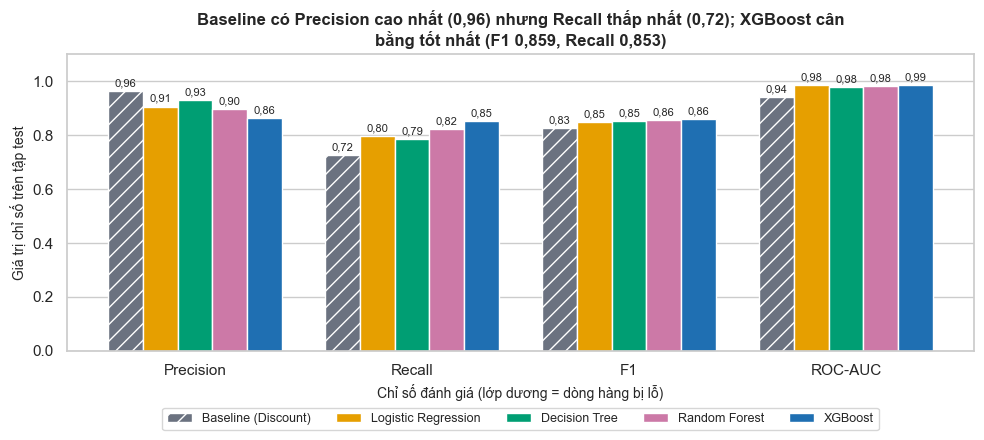

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_3_1_model_metrics.png


In [8]:
CHI_SO = ["Precision", "Recall", "F1", "ROC-AUC"]
ten_mh = list(kq.index)
x = np.arange(len(CHI_SO)); w = 0.16
fig, ax = plt.subplots(figsize=fs(12, 5.6))
for i, ten in enumerate(ten_mh):
    gia_tri = [kq.loc[ten, c] for c in CHI_SO]
    ax.bar(x + (i - 2) * w, gia_tri, width=w, color=MAU_MH[ten], label=ten, hatch="//" if ten.startswith("Baseline") else None, edgecolor="white")
    for xi, v in zip(x + (i - 2) * w, gia_tri):
        ax.annotate(vn(v, 2), (xi, v), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
ax.set_xticks(x); ax.set_xticklabels(CHI_SO)
ax.set_ylabel("Giá trị chỉ số trên tập test"); ax.set_ylim(0, 1.1); ax.set_xlabel("Chỉ số đánh giá (lớp dương = dòng hàng bị lỗ)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=5, fontsize=9)
ten_p, ten_r = kq["Precision"].idxmax(), kq["Recall"].idxmin()
if ten_p == ten_r == "Baseline (Discount)":
    tieu_de = (f"Baseline có Precision cao nhất ({vn(kq.loc[ten_p, 'Precision'], 2)}) nhưng Recall thấp nhất ({vn(kq.loc[ten_p, 'Recall'], 2)}); "
               f"{tot} cân bằng tốt nhất (F1 {vn(kq.loc[tot, 'F1'], 3)}, Recall {vn(kq.loc[tot, 'Recall'], 3)})")
else:
    tieu_de = f"{tot} có F1 cao nhất ({vn(kq.loc[tot, 'F1'], 3)}) và Recall {vn(kq.loc[tot, 'Recall'], 3)}"
ax.set_title(tieu_de, fontsize=12)
fig.tight_layout()
luu(fig, "1_model_metrics")

### Hình 4_3_2. Đường ROC của 5 mô hình

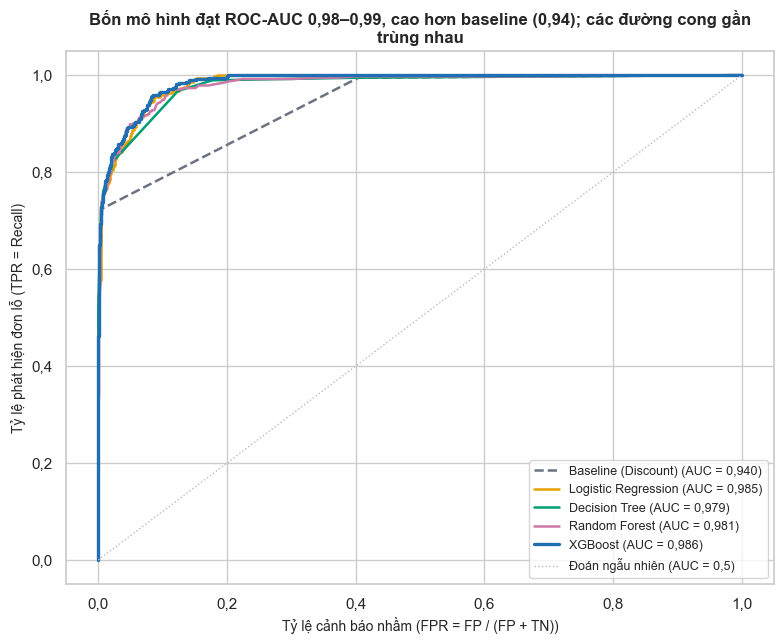

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_3_2_roc_curves.png


In [9]:
fig, ax = plt.subplots(figsize=fs(8, 6.6))
for ten in ten_mh:
    fpr, tpr, _ = roc_curve(y_test, xac_suat[ten])
    ax.plot(fpr, tpr, color=MAU_MH[ten], lw=2.4 if ten == "XGBoost" else 1.8, ls="--" if ten.startswith("Baseline") else "-",
            label=f"{ten} (AUC = {vn(kq.loc[ten, 'ROC-AUC'], 3)})")
ax.plot([0, 1], [0, 1], color="#BBBBBB", lw=1, ls=":", label="Đoán ngẫu nhiên (AUC = 0,5)")
ax.set_xlabel("Tỷ lệ cảnh báo nhầm (FPR = FP / (FP + TN))"); ax.set_ylabel("Tỷ lệ phát hiện đơn lỗ (TPR = Recall)")
ax.grid(axis="x", visible=True); ax.legend(loc="lower right", fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v, 1))); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v, 1)))
auc_4 = kq.drop(index="Baseline (Discount)")["ROC-AUC"]
ax.set_title(f"Bốn mô hình đạt ROC-AUC {vn(auc_4.min(), 2)}–{vn(auc_4.max(), 2)}, cao hơn baseline ({vn(kq.loc['Baseline (Discount)', 'ROC-AUC'], 2)}); các đường cong gần trùng nhau", fontsize=12)
fig.tight_layout()
luu(fig, "2_roc_curves")

### Hình 4_3_3. Ma trận nhầm lẫn của baseline và XGBoost

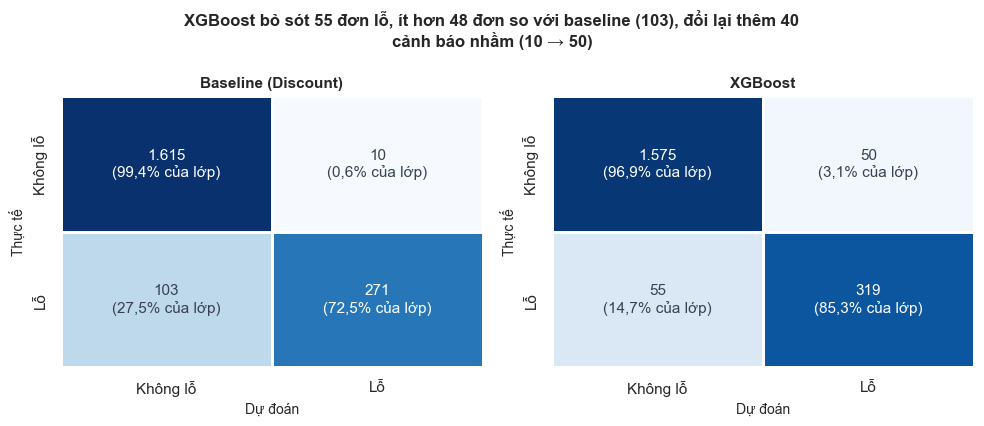

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_3_3_confusion_matrices.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=fs(12, 5.2))
nhan_lop = ["Không lỗ", "Lỗ"]
for ax, ten in zip(axes, ["Baseline (Discount)", "XGBoost"]):
    cm = confusion_matrix(y_test, du_doan[ten])
    cm_hang = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_hang, annot=False, cmap="Blues", vmin=0, vmax=1, cbar=False, linewidths=1, linecolor="white", ax=ax,
                xticklabels=nhan_lop, yticklabels=nhan_lop)
    for i in range(2):
        for j in range(2):
            ax.text(j + 0.5, i + 0.5, f"{vn(cm[i, j])}\n({pct(cm_hang[i, j] * 100)} của lớp)", ha="center", va="center", fontsize=11,
                    color="white" if cm_hang[i, j] > 0.5 else INK)
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title(ten); ax.grid(False)
fn_b, fn_x = int(kq.loc["Baseline (Discount)", "FN"]), int(kq.loc["XGBoost", "FN"])
fp_b, fp_x = int(kq.loc["Baseline (Discount)", "FP"]), int(kq.loc["XGBoost", "FP"])
fig.suptitle(f"XGBoost bỏ sót {vn(fn_x)} đơn lỗ, ít hơn {vn(fn_b - fn_x)} đơn so với baseline ({vn(fn_b)}), đổi lại thêm {vn(fp_x - fp_b)} cảnh báo nhầm ({vn(fp_b)} → {vn(fp_x)})",
             fontsize=12, fontweight="bold")
fig.tight_layout()
luu(fig, "3_confusion_matrices")

### Bước 7. Kiểm tra overfitting: F1 cross-validation và F1 test
Nếu F1 CV (trên tập train) cao hơn nhiều so với F1 test thì mô hình đang ghi nhớ dữ liệu huấn luyện.

In [11]:
qua_khop = kq.drop(index="Baseline (Discount)")[["F1 CV (5-fold)", "F1", "Chênh F1 CV − F1 test"]].round(4)
display(qua_khop)
kem_nhat = qua_khop["Chênh F1 CV − F1 test"].abs().idxmax()
nhan_xet(f"F1 CV không cao hơn F1 test ở mô hình nào: chênh lệch (F1 CV − F1 test) nằm trong khoảng {vn(qua_khop['Chênh F1 CV − F1 test'].min(), 3)} đến {vn(qua_khop['Chênh F1 CV − F1 test'].max(), 3)}. "
         f"Với XGBoost, F1 CV là {vn(kq.loc['XGBoost', 'F1 CV (5-fold)'], 3)} và F1 test là {vn(kq.loc['XGBoost', 'F1'], 3)}, gần như bằng nhau; "
         f"chênh lớn nhất ở {kem_nhat} ({vn(qua_khop.loc[kem_nhat, 'F1 CV (5-fold)'], 3)} so với {vn(qua_khop.loc[kem_nhat, 'F1'], 3)}). Vì vậy không có dấu hiệu overfitting đáng kể.")

,F1 CV (5-fold),F1,Chênh F1 CV − F1 test
Mô hình,,,
Logistic Regression,0.8351,0.8478,-0.0127
Decision Tree,0.8496,0.8522,-0.0026
Random Forest,0.8313,0.8563,-0.0251
XGBoost,0.8582,0.8587,-0.0005


**Nhận xét.** F1 CV không cao hơn F1 test ở mô hình nào: chênh lệch (F1 CV − F1 test) nằm trong khoảng −0,025 đến −0,001. Với XGBoost, F1 CV là 0,858 và F1 test là 0,859, gần như bằng nhau; chênh lớn nhất ở Random Forest (0,831 so với 0,856). Vì vậy không có dấu hiệu overfitting đáng kể.

### Bước 8. Giá trị kinh doanh: tiền lỗ bị bỏ sót (FN)
Đơn lỗ bị mô hình bỏ sót (FN) là đơn không được cảnh báo nhưng vẫn lỗ. Tổng số tiền lỗ của các đơn này trên tập test cho biết mô hình "cứu" được bao nhiêu.

In [12]:
tong_lo_test = -loi_test[y_test == 1].sum()
bs_b, bs_x = kq.loc["Baseline (Discount)", "Tiền lỗ bị bỏ sót (USD)"], kq.loc["XGBoost", "Tiền lỗ bị bỏ sót (USD)"]
giam = (1 - bs_x / bs_b) * 100
bang_bs = pd.DataFrame({"FN (số đơn bỏ sót)": kq["FN"], "Tiền lỗ bị bỏ sót (USD)": kq["Tiền lỗ bị bỏ sót (USD)"].round(0),
                        "% trên tổng lỗ của tập test": (kq["Tiền lỗ bị bỏ sót (USD)"] / tong_lo_test * 100).round(1)})
display(bang_bs)
print(f"Tổng tiền lỗ của các đơn lỗ trong tập test: {tong_lo_test:,.0f} USD")
nhan_xet(f"Trên tập test, các đơn lỗ có tổng tiền lỗ {vn(tong_lo_test)} USD. Baseline bỏ sót {vn(bs_b)} USD ({pct(bs_b / tong_lo_test * 100)}), "
         f"XGBoost bỏ sót {vn(bs_x)} USD ({pct(bs_x / tong_lo_test * 100)}), tức giảm {pct(giam)} số tiền lỗ không được cảnh báo.")

,FN (số đơn bỏ sót),Tiền lỗ bị bỏ sót (USD),% trên tổng lỗ của tập test
Mô hình,,,
Baseline (Discount),103,3496.0,10.4
Logistic Regression,76,2318.0,6.9
Decision Tree,80,2664.0,8.0
Random Forest,67,2034.0,6.1
XGBoost,55,1682.0,5.0


Tổng tiền lỗ của các đơn lỗ trong tập test: 33,474 USD


**Nhận xét.** Trên tập test, các đơn lỗ có tổng tiền lỗ 33.474 USD. Baseline bỏ sót 3.496 USD (10,4%), XGBoost bỏ sót 1.682 USD (5,0%), tức giảm 51,9% số tiền lỗ không được cảnh báo.

### Bước 9. Mức độ quan trọng của đặc trưng: permutation importance
Xáo trộn ngẫu nhiên từng cột **gốc** trên tập test (10 lần) và đo mức giảm F1 của XGBoost; cột nào làm F1 giảm nhiều nhất là cột quan trọng nhất. Tính theo 9 cột gốc (không tách one-hot) nên Sub-Category và Ship Mode được tính là một cột.

In [13]:
pi = permutation_importance(mo_hinh["XGBoost"], X_test, y_test, scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
quan_trong = pd.DataFrame({"Đặc trưng": X_test.columns, "Giảm F1 trung bình": pi.importances_mean, "Độ lệch chuẩn": pi.importances_std}).sort_values("Giảm F1 trung bình", ascending=False)
quan_trong.round(6).to_csv(REPORTS / "4_3_permutation_importance.csv", index=False, encoding="utf-8-sig")
display(quan_trong.round(4))

,Đặc trưng,Giảm F1 trung bình,Độ lệch chuẩn
7,Discount,0.6393,0.0209
4,Sub-Category,0.0571,0.0050
5,Sales,0.0344,0.0085
6,Quantity,0.0134,0.0037
3,Category,0.0067,0.0067
8,Order Month,0.0052,0.0057
2,Region,0.0036,0.0058
0,Ship Mode,-0.0021,0.0044
1,Segment,-0.0039,0.0046


### Hình 4_3_4. Permutation importance của XGBoost

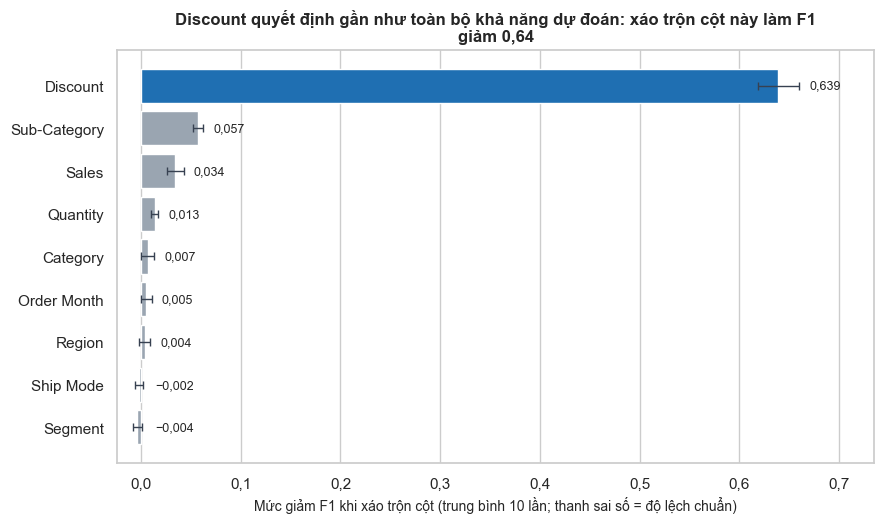

Đã lưu hình: /Users/nguyenquochung/Desktop/Năm 4/HK1/Khoa học dữ liệu/BCCM/KHDL_Superstore/figures/4_3_4_permutation_importance.png


**Nhận xét.** Xáo trộn Discount làm F1 giảm 0,639, gấp 11 lần cột quan trọng thứ hai (Sub-Category: 0,057) và thứ ba (Sales: 0,034). Năm cột còn lại gần như không đóng góp (tối đa 0,007), một số cột thậm chí có giá trị âm nhỏ do nhiễu.

In [14]:
qt = quan_trong.sort_values("Giảm F1 trung bình")
fig, ax = plt.subplots(figsize=fs(9, 5.4))
ax.barh(qt["Đặc trưng"], qt["Giảm F1 trung bình"], xerr=qt["Độ lệch chuẩn"], color=[FOCUS if v == "Discount" else NEUTRAL for v in qt["Đặc trưng"]],
        error_kw=dict(ecolor=INK, capsize=3, lw=1))
for i, (v, s) in enumerate(zip(qt["Giảm F1 trung bình"], qt["Độ lệch chuẩn"])):
    ax.text(max(v, 0) + s + 0.01, i, vn(v, 3), va="center", fontsize=9)
ax.set_xlabel("Mức giảm F1 khi xáo trộn cột (trung bình 10 lần; thanh sai số = độ lệch chuẩn)"); ax.set_ylabel("")
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: vn(v, 1)))
ax.set_xlim(qt["Giảm F1 trung bình"].min() - 0.02, qt["Giảm F1 trung bình"].max() * 1.15)
dau = quan_trong.iloc[0]
ax.set_title(f"{dau['Đặc trưng']} quyết định gần như toàn bộ khả năng dự đoán: xáo trộn cột này làm F1 giảm {vn(dau['Giảm F1 trung bình'], 2)}", fontsize=12)
fig.tight_layout()
luu(fig, "4_permutation_importance")
top_2, top_3 = quan_trong.iloc[1], quan_trong.iloc[2]
nhan_xet(f"Xáo trộn {dau['Đặc trưng']} làm F1 giảm {vn(dau['Giảm F1 trung bình'], 3)}, gấp {vn(dau['Giảm F1 trung bình'] / top_2['Giảm F1 trung bình'], 0)} lần cột quan trọng thứ hai "
         f"({top_2['Đặc trưng']}: {vn(top_2['Giảm F1 trung bình'], 3)}) và thứ ba ({top_3['Đặc trưng']}: {vn(top_3['Giảm F1 trung bình'], 3)}). "
         f"Năm cột còn lại gần như không đóng góp (tối đa {vn(quan_trong.iloc[4:]['Giảm F1 trung bình'].max(), 3)}), một số cột thậm chí có giá trị âm nhỏ do nhiễu.")

### Bước 10. Hệ số của Logistic Regression: nhóm hàng làm tăng hoặc giảm nguy cơ lỗ
Hệ số dương làm tăng nguy cơ lỗ (log-odds), hệ số âm làm giảm, **khi giữ các đặc trưng khác không đổi** (chủ yếu là mức giảm giá). Các biến số đã chuẩn hóa nên hệ số của Discount tính theo một độ lệch chuẩn.

In [15]:
lr = mo_hinh["Logistic Regression"]
he_so = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
sub = he_so[he_so.index.str.startswith("cat__Sub-Category_")]
sub.index = sub.index.str.replace("cat__Sub-Category_", "", regex=False)
sub = sub.sort_values(ascending=False)
bang_hs = pd.concat([pd.DataFrame({"Nhóm": "Tăng nguy cơ lỗ", "Sub-Category": sub.head(5).index, "Hệ số": sub.head(5).values}),
                     pd.DataFrame({"Nhóm": "Giảm nguy cơ lỗ", "Sub-Category": sub.tail(5).index[::-1], "Hệ số": sub.tail(5).values[::-1]})], ignore_index=True)
bang_hs.round(6).to_csv(REPORTS / "4_3_logistic_coefficients.csv", index=False, encoding="utf-8-sig")
display(bang_hs.round(3))
print("Hệ số Discount (chuẩn hóa):", round(he_so["num__Discount"], 3), "| C tốt nhất:", lr.named_steps["clf"].C)
nhan_xet(f"Ở cùng mức giảm giá, các nhóm hàng làm tăng nguy cơ lỗ nhiều nhất là {', '.join(sub.head(5).index)}; các nhóm làm giảm nguy cơ nhiều nhất là {', '.join(sub.tail(5).index[::-1])}. "
         f"Discount có hệ số lớn nhất ({vn(he_so['num__Discount'], 2)} trên một độ lệch chuẩn), cùng chiều với kết quả permutation importance. "
         f"Lưu ý Category và Sub-Category cùng có mặt trong mô hình nên hệ số từng nhóm hàng có thể chịu ảnh hưởng của đa cộng tuyến; chỉ nên đọc theo thứ hạng.")

,Nhóm,Sub-Category,Hệ số
0,Tăng nguy cơ lỗ,Storage,4.423
1,Tăng nguy cơ lỗ,Supplies,3.971
2,Tăng nguy cơ lỗ,Accessories,2.930
3,Tăng nguy cơ lỗ,Fasteners,2.704
4,Tăng nguy cơ lỗ,Bookcases,1.290
5,Giảm nguy cơ lỗ,Copiers,-4.268
6,Giảm nguy cơ lỗ,Paper,-3.093
7,Giảm nguy cơ lỗ,Binders,-2.964
8,Giảm nguy cơ lỗ,Art,-2.519
9,Giảm nguy cơ lỗ,Labels,-1.657


Hệ số Discount (chuẩn hóa): 5.929 | C tốt nhất: 10


**Nhận xét.** Ở cùng mức giảm giá, các nhóm hàng làm tăng nguy cơ lỗ nhiều nhất là Storage, Supplies, Accessories, Fasteners, Bookcases; các nhóm làm giảm nguy cơ nhiều nhất là Copiers, Paper, Binders, Art, Labels. Discount có hệ số lớn nhất (5,93 trên một độ lệch chuẩn), cùng chiều với kết quả permutation importance. Lưu ý Category và Sub-Category cùng có mặt trong mô hình nên hệ số từng nhóm hàng có thể chịu ảnh hưởng của đa cộng tuyến; chỉ nên đọc theo thứ hạng.

### Bước 11. Kiểm tra bổ sung: chia theo Order ID
Chia ngẫu nhiên theo dòng có thể đặt các dòng cùng một đơn vào cả tập train và test. Kiểm tra bằng cách chia theo **Order ID** (`GroupShuffleSplit`, 3 hạt ngẫu nhiên) với XGBoost dùng tham số tốt nhất ở trên, để xem kết quả có phụ thuộc vào cách chia hay không. Đây là kiểm tra thêm, không thay thế kết quả chính.

In [16]:
tham_so_xgb = {k.replace("clf__", ""): v for k, v in
               [(kv.split("=")[0], (float(kv.split("=")[1]) if "." in kv.split("=")[1] else int(kv.split("=")[1]))) for kv in thong_tin["XGBoost"]["tham_so"].split(", ")]}
dong = []
for hat in (42, 1, 2):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=hat).split(X, y, groups=df["Order ID"]))
    xgb_g = Pipeline([("pre", tien_xu_ly()), ("clf", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=4, **tham_so_xgb))]).fit(X.iloc[tr], y.iloc[tr])
    base_g = Pipeline([("chon", ColumnTransformer([("d", "passthrough", ["Discount"])])), ("clf", DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE))]).fit(X.iloc[tr], y.iloc[tr])
    for ten, m in (("XGBoost", xgb_g), ("Baseline (Discount)", base_g)):
        p = m.predict(X.iloc[te])
        dong.append({"Hạt ngẫu nhiên": hat, "Mô hình": ten, "F1": f1_score(y.iloc[te], p), "Recall": recall_score(y.iloc[te], p),
                     "ROC-AUC": roc_auc_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1])})
chia_nhom = pd.DataFrame(dong)
chia_nhom.round(6).to_csv(REPORTS / "4_3_group_split_check.csv", index=False, encoding="utf-8-sig")
display(chia_nhom.round(3))
f1_x = chia_nhom.loc[chia_nhom["Mô hình"] == "XGBoost", "F1"]
nhan_xet(f"Khi chia theo đơn hàng, F1 của XGBoost nằm trong khoảng {vn(f1_x.min(), 3)}–{vn(f1_x.max(), 3)} (chia theo dòng: {vn(kq.loc['XGBoost', 'F1'], 3)}), "
         f"vẫn cao hơn baseline ở cả 3 hạt ngẫu nhiên; kết quả không phụ thuộc vào việc các dòng cùng đơn nằm chung một tập.")

,Hạt ngẫu nhiên,Mô hình,F1,Recall,ROC-AUC
0,42,XGBoost,0.852,0.827,0.984
1,42,Baseline (Discount),0.827,0.722,0.942
2,1,XGBoost,0.871,0.844,0.990
3,1,Baseline (Discount),0.829,0.721,0.942
4,2,XGBoost,0.851,0.816,0.984
5,2,Baseline (Discount),0.820,0.716,0.935


**Nhận xét.** Khi chia theo đơn hàng, F1 của XGBoost nằm trong khoảng 0,851–0,871 (chia theo dòng: 0,859), vẫn cao hơn baseline ở cả 3 hạt ngẫu nhiên; kết quả không phụ thuộc vào việc các dòng cùng đơn nằm chung một tập.

### Bước 12. Trả lời Câu hỏi 4

In [17]:
display(Markdown(f'''
**Dự đoán được đơn lỗ không?** Có. {tot} đạt F1 = {vn(kq.loc[tot, "F1"], 3)}, Recall = {vn(kq.loc[tot, "Recall"], 3)} và ROC-AUC = {vn(kq.loc[tot, "ROC-AUC"], 3)} trên tập test {vn(len(X_test))} dòng.

**Mô hình nào tốt nhất?** {tot} có F1 cao nhất, nhưng khác biệt giữa các mô hình không lớn (F1 từ {vn(kq.drop(index="Baseline (Discount)")["F1"].min(), 3)} đến {vn(kq.drop(index="Baseline (Discount)")["F1"].max(), 3)}) và
luật đơn giản chỉ dùng Discount đã đạt F1 = {vn(kq.loc["Baseline (Discount)", "F1"], 3)}. Phần lớn giá trị dự đoán đến từ Discount; các mô hình ML chủ yếu cải thiện Recall
(từ {vn(kq.loc["Baseline (Discount)", "Recall"], 3)} lên {vn(kq.loc["XGBoost", "Recall"], 3)}) và giảm số đơn lỗ bị bỏ sót từ {vn(fn_b)} xuống {vn(fn_x)}.

**Yếu tố quan trọng nhất?** {dau["Đặc trưng"]} (xáo trộn làm F1 giảm {vn(dau["Giảm F1 trung bình"], 3)}), tiếp theo là {top_2["Đặc trưng"]} ({vn(top_2["Giảm F1 trung bình"], 3)}) và {top_3["Đặc trưng"]} ({vn(top_3["Giảm F1 trung bình"], 3)}).

**Ứng dụng thực tế:** dùng mô hình để cảnh báo đơn có nguy cơ lỗ trước khi duyệt giảm giá, ưu tiên Recall vì bỏ sót một đơn lỗ tốn kém hơn một cảnh báo nhầm. Trên tập test, XGBoost giảm tiền lỗ không được cảnh báo từ {vn(bs_b)} xuống {vn(bs_x)} USD (giảm {pct(giam)}).

**Hạn chế:** nhãn được định nghĩa theo dòng hàng chứ không theo đơn hàng; dữ liệu mô phỏng nên độ chính xác cao có thể không giữ nguyên trên dữ liệu thực; chưa kiểm chứng trên dữ liệu độc lập theo thời gian.
'''))


**Dự đoán được đơn lỗ không?** Có. XGBoost đạt F1 = 0,859, Recall = 0,853 và ROC-AUC = 0,986 trên tập test 1.999 dòng.

**Mô hình nào tốt nhất?** XGBoost có F1 cao nhất, nhưng khác biệt giữa các mô hình không lớn (F1 từ 0,848 đến 0,859) và
luật đơn giản chỉ dùng Discount đã đạt F1 = 0,827. Phần lớn giá trị dự đoán đến từ Discount; các mô hình ML chủ yếu cải thiện Recall
(từ 0,725 lên 0,853) và giảm số đơn lỗ bị bỏ sót từ 103 xuống 55.

**Yếu tố quan trọng nhất?** Discount (xáo trộn làm F1 giảm 0,639), tiếp theo là Sub-Category (0,057) và Sales (0,034).

**Ứng dụng thực tế:** dùng mô hình để cảnh báo đơn có nguy cơ lỗ trước khi duyệt giảm giá, ưu tiên Recall vì bỏ sót một đơn lỗ tốn kém hơn một cảnh báo nhầm. Trên tập test, XGBoost giảm tiền lỗ không được cảnh báo từ 3.496 xuống 1.682 USD (giảm 51,9%).

**Hạn chế:** nhãn được định nghĩa theo dòng hàng chứ không theo đơn hàng; dữ liệu mô phỏng nên độ chính xác cao có thể không giữ nguyên trên dữ liệu thực; chưa kiểm chứng trên dữ liệu độc lập theo thời gian.


### Bước 13. Đối chiếu với kết quả kỳ vọng
So sánh với các số tham chiếu. Chỉ số mô hình (F1, Recall, ROC-AUC) cho phép lệch tối đa ±0,01; số đơn FN lệch tối đa 5; tiền lỗ bị bỏ sót lệch tối đa 5%. Kết quả của XGBoost có thể lệch nhẹ theo phiên bản thư viện.

In [18]:
THAM_CHIEU = {  # (mô hình, chỉ số): (giá trị tham chiếu, dung sai)
    ("Baseline (Discount)", "F1"): (0.828, 0.01), ("Baseline (Discount)", "Recall"): (0.725, 0.01), ("Baseline (Discount)", "ROC-AUC"): (0.940, 0.01), ("Baseline (Discount)", "FN"): (103, 5),
    ("Logistic Regression", "F1"): (0.848, 0.01), ("Logistic Regression", "Recall"): (0.797, 0.01), ("Logistic Regression", "ROC-AUC"): (0.985, 0.01), ("Logistic Regression", "FN"): (76, 5),
    ("Decision Tree", "F1"): (0.852, 0.01), ("Decision Tree", "Recall"): (0.786, 0.01), ("Decision Tree", "ROC-AUC"): (0.979, 0.01), ("Decision Tree", "FN"): (80, 5),
    ("Random Forest", "F1"): (0.859, 0.01), ("Random Forest", "Recall"): (0.821, 0.01), ("Random Forest", "ROC-AUC"): (0.981, 0.01), ("Random Forest", "FN"): (67, 5),
    ("XGBoost", "F1"): (0.863, 0.01), ("XGBoost", "Recall"): (0.845, 0.01), ("XGBoost", "ROC-AUC"): (0.987, 0.01), ("XGBoost", "FN"): (58, 5),
    ("XGBoost", "F1 CV (5-fold)"): (0.858, 0.01),
}
dong = []
for (ten, cs), (tc, ds) in THAM_CHIEU.items():
    thuc = float(kq.loc[ten, cs]); dong.append({"Mô hình": ten, "Chỉ số": cs, "Tham chiếu": tc, "Thực tế": round(thuc, 3), "Chênh": round(thuc - tc, 3), "Dung sai": ds, "Kết quả": "ĐẠT" if abs(thuc - tc) <= ds else "LỆCH"})
so_sanh = pd.DataFrame(dong)
display(so_sanh)

perm = quan_trong.set_index("Đặc trưng")["Giảm F1 trung bình"]
kiem_tra = {
    "Nhãn lỗ: 1.870/9.993 = 18,71%; train 7.994, test 1.999": n_lo == 1870 and n_dong == 9993 and len(X_train) == 7994 and len(X_test) == 1999,
    "Mọi chỉ số mô hình nằm trong dung sai tham chiếu": bool((so_sanh["Kết quả"] == "ĐẠT").all()),
    "XGBoost có F1 cao nhất trong 4 mô hình ML": tot == "XGBoost",
    "Tiền lỗ bị bỏ sót: baseline ≈ 3.496 USD (sai số 1%)": abs(bs_b - 3496) <= 35,
    "Tiền lỗ bị bỏ sót: XGBoost ≈ 1.715 USD (sai số 5%) và giảm ≈ 51% (sai số 2 điểm %)": abs(bs_x - 1715) <= 86 and abs(giam - 51) <= 2,
    "Permutation: Discount ≈ 0,649; Sub-Category ≈ 0,058; Sales ≈ 0,031; Quantity ≈ 0,013": abs(perm["Discount"] - 0.649) <= 0.02 and abs(perm["Sub-Category"] - 0.058) <= 0.01
        and abs(perm["Sales"] - 0.031) <= 0.01 and abs(perm["Quantity"] - 0.013) <= 0.01,
    "Các biến còn lại có mức giảm F1 dưới 0,01": bool((perm.drop(["Discount", "Sub-Category", "Sales", "Quantity"]) < 0.01).all()),
}
for ten, ok in kiem_tra.items():
    print("ĐẠT " if ok else "LỆCH", "–", ten)
print()
print("Tham số tốt nhất của XGBoost:", thong_tin["XGBoost"]["tham_so"], "(tham chiếu: learning_rate=0.05, max_depth=7, n_estimators=400; có thể khác theo phiên bản xgboost)")
assert all(kiem_tra.values()), "Có kết quả lệch so với kỳ vọng, cần kiểm tra lại"
print("Tất cả kết quả khớp kỳ vọng (trong dung sai).")

,Mô hình,Chỉ số,Tham chiếu,Thực tế,Chênh,Dung sai,Kết quả
0,Baseline (Discount),F1,0.828,0.827,-0.001,0.01,ĐẠT
1,Baseline (Discount),Recall,0.725,0.725,-0.000,0.01,ĐẠT
2,Baseline (Discount),ROC-AUC,0.940,0.940,0.000,0.01,ĐẠT
3,Baseline (Discount),FN,103.000,103.000,0.000,5.00,ĐẠT
4,Logistic Regression,F1,0.848,0.848,-0.000,0.01,ĐẠT
5,Logistic Regression,Recall,0.797,0.797,-0.000,0.01,ĐẠT
6,Logistic Regression,ROC-AUC,0.985,0.985,-0.000,0.01,ĐẠT
7,Logistic Regression,FN,76.000,76.000,0.000,5.00,ĐẠT
8,Decision Tree,F1,0.852,0.852,0.000,0.01,ĐẠT
9,Decision Tree,Recall,0.786,0.786,0.000,0.01,ĐẠT


ĐẠT  – Nhãn lỗ: 1.870/9.993 = 18,71%; train 7.994, test 1.999
ĐẠT  – Mọi chỉ số mô hình nằm trong dung sai tham chiếu
ĐẠT  – XGBoost có F1 cao nhất trong 4 mô hình ML
ĐẠT  – Tiền lỗ bị bỏ sót: baseline ≈ 3.496 USD (sai số 1%)
ĐẠT  – Tiền lỗ bị bỏ sót: XGBoost ≈ 1.715 USD (sai số 5%) và giảm ≈ 51% (sai số 2 điểm %)
ĐẠT  – Permutation: Discount ≈ 0,649; Sub-Category ≈ 0,058; Sales ≈ 0,031; Quantity ≈ 0,013
ĐẠT  – Các biến còn lại có mức giảm F1 dưới 0,01

Tham số tốt nhất của XGBoost: learning_rate=0.1, max_depth=7, n_estimators=400 (tham chiếu: learning_rate=0.05, max_depth=7, n_estimators=400; có thể khác theo phiên bản xgboost)
Tất cả kết quả khớp kỳ vọng (trong dung sai).
